In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path(r"D:/Pune-House-Price-Prediction")

DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "processed" / "pune_cleaned_reference_v2.csv",
    PROJECT_ROOT / "data" / "processed" / "pune_cleaned_reference.csv"
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    None
)

MODEL_DIR = PROJECT_ROOT / "models"
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = MODEL_DIR / "model_features.json"
METRICS_PATH = MODEL_DIR / "model_comparison.csv"

if DATA_PATH is None:
    raise FileNotFoundError("Cleaned CSV not found in data/processed.")

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        "model_features.json not found. Run Notebook 3 through Cell 26 first."
    )

print("Dataset:", DATA_PATH)
print("Feature configuration:", CONFIG_PATH)

Dataset: D:\Pune-House-Price-Prediction\data\processed\pune_cleaned_reference.csv
Feature configuration: D:\Pune-House-Price-Prediction\models\model_features.json


In [3]:
df = pd.read_csv(DATA_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = json.load(file)

TARGET = config["target"]
FEATURES = config["features"]
NUMERIC_COLUMNS = config["numeric_columns"]
CATEGORICAL_COLUMNS = config["categorical_columns"]
AMENITY_COLUMNS = config["amenity_columns"]

print("Dataset shape:", df.shape)
print("Target:", TARGET)
print("Number of features:", len(FEATURES))
print("Number of numeric features:", len(NUMERIC_COLUMNS))
print("Number of categorical features:", len(CATEGORICAL_COLUMNS))
print("Number of amenities:", len(AMENITY_COLUMNS))

Dataset shape: (27700, 53)
Target: price
Number of features: 50
Number of numeric features: 8
Number of categorical features: 42
Number of amenities: 35


In [4]:
raw_path = PROJECT_ROOT / "data" / "raw" / "Pune_property_data.csv"

if raw_path.exists():
    raw_rows = len(pd.read_csv(raw_path))
    print("Raw dataset rows:", raw_rows)
    print("Current cleaned dataset rows:", len(df))
    print("Rows removed:", raw_rows - len(df))

    if len(df) == 27700:
        print(
            "\nWARNING: This is the 27,700-row dataset seen earlier. "
            "Expected cleaned row count was approximately 37,517. "
            "Verify Notebook 1 before treating tuning results as final."
        )

print("\nMissing target values:", df[TARGET].isna().sum())
print("Non-positive prices:", (pd.to_numeric(df[TARGET], errors="coerce") <= 0).sum())

Raw dataset rows: 37539
Current cleaned dataset rows: 27700
Rows removed: 9839


Missing target values: 0
Non-positive prices: 0


In [5]:
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

df = df.loc[
    df[TARGET].notna() & (df[TARGET] > 0)
].copy()

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Rows available for modelling:", len(df))
print("X shape:", X.shape)
print("y shape:", y.shape)

Rows available for modelling: 27700
X shape: (27700, 50)
y shape: (27700,)


In [6]:
for column in NUMERIC_COLUMNS:
    X[column] = pd.to_numeric(
        X[column], errors="coerce"
    ).astype(float)

for column in CATEGORICAL_COLUMNS:
    if column in AMENITY_COLUMNS:
        values = (
            X[column]
            .astype("string")
            .str.strip()
            .str.lower()
            .replace({
                "1": "yes",
                "0": "no",
                "true": "yes",
                "false": "no",
                "": pd.NA,
                "nan": pd.NA,
                "none": pd.NA
            })
        )
        X[column] = values.astype(object).where(values.notna(), np.nan)
    else:
        X[column] = (
            X[column]
            .astype(object)
            .where(X[column].notna(), np.nan)
        )

print("Feature values cleaned.")

Feature values cleaned.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 22160
Testing rows: 5540


In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Not specified"
        )
    ),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_COLUMNS),
    ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS)
])

print("Preprocessor ready.")

Preprocessor ready.


In [9]:
parameter_distributions = {
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 15, 25, 35],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [1.0, "sqrt"]
    },
    "Extra Trees": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 15, 25, 35],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [1.0, "sqrt"]
    }
}

print("Hyperparameter search spaces created.")

Hyperparameter search spaces created.


In [10]:
base_models = {
    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    )
}

search_results = {}
tuned_pipelines = {}

for model_name, base_model in base_models.items():
    print(f"\nTuning {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", base_model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_distributions[model_name],
        n_iter=6,
        scoring="neg_mean_absolute_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    search_results[model_name] = search
    tuned_pipelines[model_name] = search.best_estimator_

    print("Best cross-validation MAE:", round(-search.best_score_, 2))
    print("Best parameters:")
    print(search.best_params_)

print("\nTuning completed.")


Tuning Random Forest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best cross-validation MAE: 2056186.36
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 25}

Tuning Extra Trees...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best cross-validation MAE: 1936425.02
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 25}

Tuning completed.


In [11]:
tuning_rows = []

for model_name, search in search_results.items():
    tuning_rows.append({
        "Model": model_name,
        "Best_CV_MAE": -search.best_score_,
        "Best_Parameters": str(search.best_params_)
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    "Best_CV_MAE"
).reset_index(drop=True)

display(tuning_df)

,Model,Best_CV_MAE,Best_Parameters
0,Extra Trees,1.936425e+06,"{'model__n_estimators': 100, 'model__min_sampl..."
1,Random Forest,2.056186e+06,"{'model__n_estimators': 100, 'model__min_sampl..."


In [12]:
test_results = []

for model_name, pipeline in tuned_pipelines.items():
    predictions = pipeline.predict(X_test)

    test_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

test_results_df = pd.DataFrame(test_results).sort_values(
    "MAE"
).reset_index(drop=True)

display(test_results_df)

,Model,MAE,RMSE,R2
0,Extra Trees,1.915397e+06,4.777894e+06,0.930560
1,Random Forest,2.041424e+06,4.914985e+06,0.926518


In [13]:
if METRICS_PATH.exists():
    original_results = pd.read_csv(METRICS_PATH)

    print("Original Notebook 3 results:")
    display(original_results)

    print("Tuned model test results:")
    display(test_results_df)
else:
    print(
        "Original model comparison file not found. "
        "Tuned model results are shown above."
    )

Original Notebook 3 results:


,Model,MAE,RMSE,R2
0,Extra Trees,1.809765e+06,4.836666e+06,0.928841
1,Random Forest,1.995268e+06,4.967343e+06,0.924944


Tuned model test results:


,Model,MAE,RMSE,R2
0,Extra Trees,1.915397e+06,4.777894e+06,0.930560
1,Random Forest,2.041424e+06,4.914985e+06,0.926518


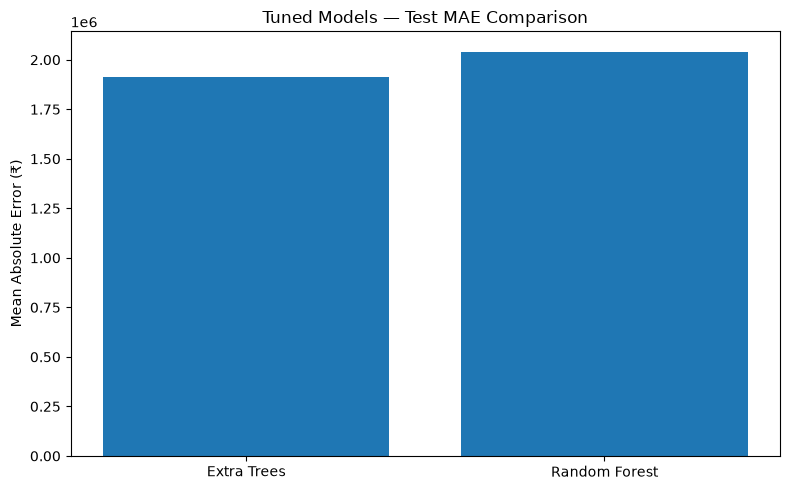

Plot saved: D:\Pune-House-Price-Prediction\visualizations\tuned_model_comparison.png


In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    test_results_df["Model"],
    test_results_df["MAE"]
)

plt.ylabel("Mean Absolute Error (₹)")
plt.title("Tuned Models — Test MAE Comparison")
plt.tight_layout()

plot_path = VISUALIZATION_DIR / "tuned_model_comparison.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Plot saved:", plot_path)

In [15]:
best_tuned_name = test_results_df.iloc[0]["Model"]
best_tuned_model = tuned_pipelines[best_tuned_name]

best_search = search_results[best_tuned_name]
best_test_row = test_results_df.iloc[0]

print("Best tuned model:", best_tuned_name)
print(f"Test MAE: ₹{best_test_row['MAE']:,.2f}")
print(f"Test RMSE: ₹{best_test_row['RMSE']:,.2f}")
print(f"Test R²: {best_test_row['R2']:.4f}")
print("\nBest hyperparameters:")
print(best_search.best_params_)

Best tuned model: Extra Trees
Test MAE: ₹1,915,397.29
Test RMSE: ₹4,777,894.06
Test R²: 0.9306

Best hyperparameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 25}


In [16]:
TUNING_RESULTS_PATH = MODEL_DIR / "tuning_results.csv"
TUNED_MODEL_PATH = MODEL_DIR / "tuned_model_candidate.joblib"
TUNING_CONFIG_PATH = MODEL_DIR / "tuning_report.json"

tuning_df.to_csv(TUNING_RESULTS_PATH, index=False)

joblib.dump(best_tuned_model, TUNED_MODEL_PATH)

tuning_report = {
    "selected_model": best_tuned_name,
    "best_parameters": best_search.best_params_,
    "best_cross_validation_mae": float(-best_search.best_score_),
    "test_mae": float(best_test_row["MAE"]),
    "test_rmse": float(best_test_row["RMSE"]),
    "test_r2": float(best_test_row["R2"]),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "dataset_file": DATA_PATH.name,
    "random_state": 42
}

with open(TUNING_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(tuning_report, file, indent=4)

print("Tuning results saved:")
print(TUNING_RESULTS_PATH)
print(TUNED_MODEL_PATH)
print(TUNING_CONFIG_PATH)

Tuning results saved:
D:\Pune-House-Price-Prediction\models\tuning_results.csv
D:\Pune-House-Price-Prediction\models\tuned_model_candidate.joblib
D:\Pune-House-Price-Prediction\models\tuning_report.json


In [17]:
for path in [
    TUNING_RESULTS_PATH,
    TUNED_MODEL_PATH,
    TUNING_CONFIG_PATH,
    VISUALIZATION_DIR / "tuned_model_comparison.png"
]:
    print(f"{'OK' if path.exists() else 'MISSING'}: {path}")

OK: D:\Pune-House-Price-Prediction\models\tuning_results.csv
OK: D:\Pune-House-Price-Prediction\models\tuned_model_candidate.joblib
OK: D:\Pune-House-Price-Prediction\models\tuning_report.json
OK: D:\Pune-House-Price-Prediction\visualizations\tuned_model_comparison.png
